# Image Mining, Part 1: content-based image retrieval

Zahra Soukhtedel

## 0. Environment

In [2]:
import os, time, zipfile, urllib.request
from pathlib import Path

import av
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn.functional as F

DATA_DIR = Path(os.environ.get("DATA_DIR", "/content" if Path("/content").exists() else "."))
ZIP_URL = "https://perso.ensta.fr/~manzaner/Cours/Masters_ParisSaclay/Image_Mining/Video_Mining_Examples.zip"
zip_path = DATA_DIR / "Video_Mining_Examples.zip"
video_path = DATA_DIR / "Projet2_Videos" / "Extrait3-Vertigo-Dream_Scene(320p).m4v"
portrait_path = DATA_DIR / "Portrait_of_a_Lady_Bernardino_Zaganelli_-_circa_1500.jpg"

if not video_path.exists():
    if not zip_path.exists():
        print("Downloading the videos ...")
        urllib.request.urlretrieve(ZIP_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

assert video_path.exists(), video_path
assert portrait_path.exists(), "download the Zaganelli portrait from Wikimedia Commons first"

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(0)
print("torch", torch.__version__, "| av", av.__version__, "| device:", device)

torch 2.8.0 | av 15.1.0 | device: mps


## 1. Video metadata

In [3]:
with av.open(str(video_path)) as container:
    stream = container.streams.video[0]
    duration_s = float(stream.duration * stream.time_base)
    frame_rate_fps = int(stream.frames) / duration_s
    n_frames = int(stream.frames)
    width, height = stream.codec_context.width, stream.codec_context.height

print(f"duration   : {duration_s:.2f} s")
print(f"frame rate : {frame_rate_fps:.2f} fps")
print(f"frames     : {n_frames}")
print(f"resolution : {width} x {height}")

duration   : 95.00 s
frame rate : 25.00 fps
frames     : 2375
resolution : 560 x 320


## 2. Gallery

In [4]:
gallery_size = 150
target_times_s = np.linspace(2.0, duration_s - 2.0, gallery_size)

gallery = []
needed_frames = {350, 356}
kept_frames = {}
next_target = 0

with av.open(str(video_path)) as container:
    for frame_index, frame in enumerate(container.decode(video=0)):
        if frame_index in needed_frames:
            kept_frames[frame_index] = frame.to_ndarray(format="rgb24")
        if next_target == gallery_size and len(kept_frames) == len(needed_frames):
            break
        if next_target < gallery_size and float(frame.time) >= target_times_s[next_target]:
            gallery.append({
                "gallery_id": f"vertigo_{next_target:03d}",
                "image": frame.to_ndarray(format="rgb24"),
                "frame_index": frame_index,
                "timestamp_s": float(frame.time),
            })
            next_target += 1

gallery_images = [g["image"] for g in gallery]
gallery_frame_idx = np.array([g["frame_index"] for g in gallery])
gallery_time = np.array([g["timestamp_s"] for g in gallery])

print("gallery size:", len(gallery), "| frame shape:", gallery_images[0].shape)
print("vertigo_020 ->", gallery[20]["frame_index"], gallery[20]["timestamp_s"], "s")
print("gap between gallery frames:", np.diff(gallery_frame_idx).min(), "to", np.diff(gallery_frame_idx).max(), "frames")

gallery size: 150 | frame shape: (320, 560, 3)
vertigo_020 -> 356 14.24 s
gap between gallery frames: 15 to 16 frames


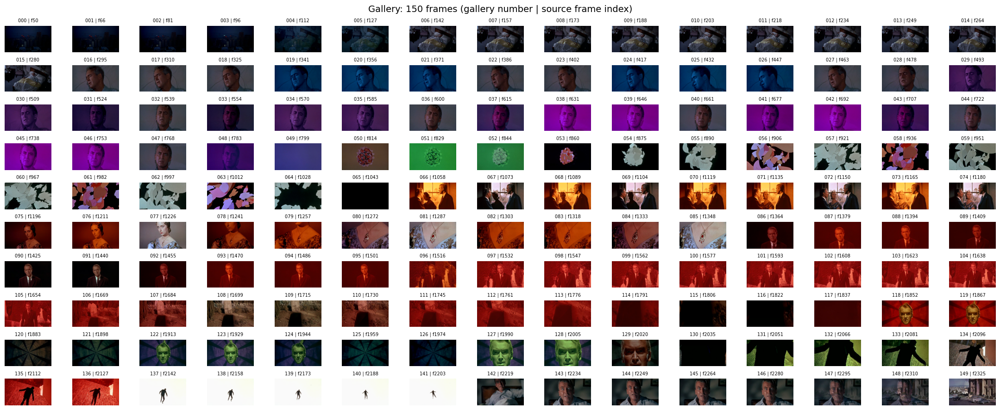

In [5]:
fig, axes = plt.subplots(10, 15, figsize=(22, 9))
for ax, g in zip(axes.ravel(), gallery):
    ax.imshow(g["image"])
    ax.set_title(f'{g["gallery_id"][-3:]} | f{g["frame_index"]}', fontsize=7)
    ax.axis("off")
fig.suptitle("Gallery: 150 frames (gallery number | source frame index)", fontsize=14)
plt.tight_layout()
plt.show()

## 3. Queries

In [6]:
crop_box = (160, 40, 360, 240)

frame_356 = kept_frames[356]
frame_350 = kept_frames[350]
assert np.array_equal(frame_356, gallery[20]["image"])

queries = {
    "whole_frame": frame_356,
    "in_gallery_crop": np.array(Image.fromarray(frame_356).crop(crop_box)),
    "held_out_crop": np.array(Image.fromarray(frame_350).crop(crop_box)),
    "external": np.array(Image.open(portrait_path).convert("RGB")),
}
query_names = list(queries)
for name, img in queries.items():
    print(f"{name:16s} {img.shape}")

whole_frame      (320, 560, 3)
in_gallery_crop  (200, 200, 3)
held_out_crop    (200, 200, 3)
external         (342, 250, 3)


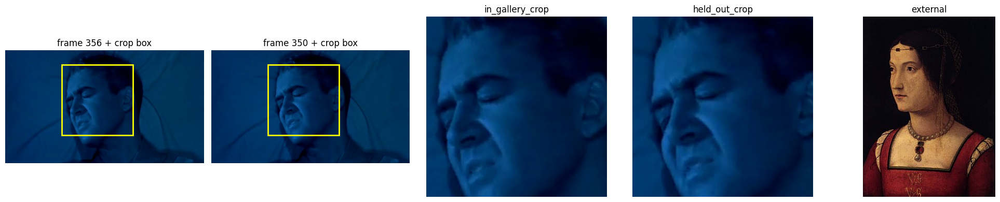

mean absolute pixel difference between the two crops: 9.65 (out of 255)


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (title, img) in zip(axes[:2], [("frame 356 + crop box", frame_356), ("frame 350 + crop box", frame_350)]):
    ax.imshow(img)
    l, t, r, b = crop_box
    ax.add_patch(patches.Rectangle((l, t), r - l, b - t, fill=False, edgecolor="yellow", lw=2))
    ax.set_title(title); ax.axis("off")
for ax, name in zip(axes[2:], ["in_gallery_crop", "held_out_crop", "external"]):
    ax.imshow(queries[name]); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

diff = np.abs(queries["in_gallery_crop"].astype(int) - queries["held_out_crop"].astype(int))
print(f"mean absolute pixel difference between the two crops: {diff.mean():.2f} (out of 255)")

## 4. Functions used in every experiment

In [8]:
TOP_K = 5

def rank(scores):
    return np.argsort(-np.asarray(scores), kind="stable")

def is_relevant(query_name, g):
    if query_name in ("whole_frame", "in_gallery_crop"):
        return gallery_frame_idx[g] == 356
    if query_name == "held_out_crop":
        return gallery_frame_idx[g] == 356
    if query_name == "external":
        return 1184 <= gallery_frame_idx[g] <= 1350

def evaluate(query_name, order):
    k = 1 if query_name in ("whole_frame", "in_gallery_crop") else 3
    passed = any(is_relevant(query_name, g) for g in order[:k])
    first = next((r + 1 for r, g in enumerate(order) if is_relevant(query_name, g)), None)
    return passed, first

def checks_table(similarity_dict, label="method"):
    rows = []
    for variant, S in similarity_dict.items():
        S = np.asarray(S)
        row = {label: variant}
        for qi, name in enumerate(query_names):
            ok, first = evaluate(name, rank(S[qi]))
            row[name] = f"{'PASS' if ok else 'fail'} (first hit: {first})"
        rows.append(row)
    return pd.DataFrame(rows).set_index(label)

def report(method_name, S):
    rows = []
    for qi, name in enumerate(query_names):
        order = rank(S[qi])
        ok, first = evaluate(name, order)
        rows.append({
            "query": name,
            "criterion": "top-1" if name in ("whole_frame", "in_gallery_crop") else "top-3",
            "passed": "PASS" if ok else "FAIL",
            "first relevant rank": first,
            "top-5 frame indices": [int(gallery_frame_idx[g]) for g in order[:TOP_K]],
            "top-5 scores": [round(float(S[qi, g]), 4) for g in order[:TOP_K]],
        })
    df = pd.DataFrame(rows)
    df.index = [method_name] * len(df)
    return df

def show_panel(query_name, S_row, method_name, k=TOP_K):
    order = rank(S_row)[:k]
    fig, axes = plt.subplots(1, k + 1, figsize=(3.3 * (k + 1), 3.6),
                             gridspec_kw={"width_ratios": [1.1] + [1.75] * k})
    axes[0].imshow(queries[query_name]); axes[0].set_title(f"QUERY\n{query_name}", fontsize=10); axes[0].axis("off")
    for r, g in enumerate(order, start=1):
        ax = axes[r]
        ax.imshow(gallery_images[g])
        ax.set_title(f"rank {r} | score {S_row[g]:.4f}\n{gallery[g]['gallery_id']}\n"
                     f"frame {gallery_frame_idx[g]} | {gallery_time[g]:.2f} s", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor("limegreen" if is_relevant(query_name, g) else "red"); s.set_linewidth(4)
    fig.suptitle(f"{method_name} - {query_name}", fontsize=12)
    plt.tight_layout(); plt.show()

all_results = []

## 5.1 Histograms

### Try 1: grey-level histogram

In [9]:
eps = 1e-10

def histogram_metrics(H_q, H_g):
    Hq, Hg = torch.tensor(H_q, dtype=torch.float64), torch.tensor(H_g, dtype=torch.float64)
    P, Q = Hq / Hq.sum(1, keepdim=True), Hg / Hg.sum(1, keepdim=True)
    return {
        "cosine":                    F.normalize(P, dim=1) @ F.normalize(Q, dim=1).T,
        "Bhattacharyya":             P.sqrt() @ Q.sqrt().T,
        "-chi2":                     -0.5 * ((P[:, None] - Q[None]) ** 2 / (P[:, None] + Q[None] + eps)).sum(-1),
        "-KL(query||gallery)":       -(P[:, None] * ((P[:, None] + eps).log() - (Q[None] + eps).log())).sum(-1),
        "intersection (normalised)": torch.minimum(P[:, None], Q[None]).sum(-1),
        "intersection (counts)":     torch.minimum(Hq[:, None], Hg[None]).sum(-1) / Hq.sum(1, keepdim=True),
    }

def grey_histogram(image):
    grey = np.array(Image.fromarray(image).convert("L"))
    return np.bincount(grey.ravel(), minlength=256).astype(np.float64)

G_gallery = np.stack([grey_histogram(im) for im in gallery_images])
G_query = np.stack([grey_histogram(queries[n]) for n in query_names])
grey_metrics = histogram_metrics(G_query, G_gallery)
checks_table({k: grey_metrics[k].numpy() for k in ["cosine", "-KL(query||gallery)"]}, "grey histogram +")

,whole_frame,in_gallery_crop,held_out_crop,external
grey histogram +,,,,
cosine,PASS (first hit: 1),fail (first hit: 40),fail (first hit: 34),fail (first hit: 4)
-KL(query||gallery),PASS (first hit: 1),fail (first hit: 19),fail (first hit: 23),fail (first hit: 24)


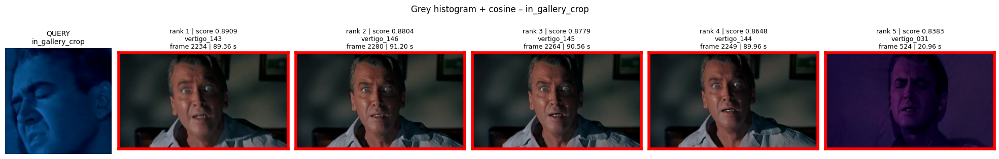

In [10]:
show_panel("in_gallery_crop", grey_metrics["cosine"][1].numpy(), "Grey histogram + cosine")

### Try 2: joint RGB histogram

In [11]:
BINS_PER_CHANNEL = 16

def rgb_histogram(image, bins=BINS_PER_CHANNEL):
    q = (image.astype(np.int64) * bins) // 256
    idx = (q[..., 0] * bins + q[..., 1]) * bins + q[..., 2]
    return np.bincount(idx.ravel(), minlength=bins ** 3).astype(np.float64)

t0 = time.time()
H_gallery = np.stack([rgb_histogram(im) for im in gallery_images])
H_query = np.stack([rgb_histogram(queries[n]) for n in query_names])
print(f"gallery histograms {H_gallery.shape}, queries {H_query.shape}, computed in {time.time() - t0:.2f} s")
print("non-empty cells per query:", dict(zip(query_names, (H_query > 0).sum(1).tolist())))

gallery histograms (150, 4096), queries (4, 4096), computed in 0.16 s
non-empty cells per query: {'whole_frame': 39, 'in_gallery_crop': 37, 'held_out_crop': 43, 'external': 290}


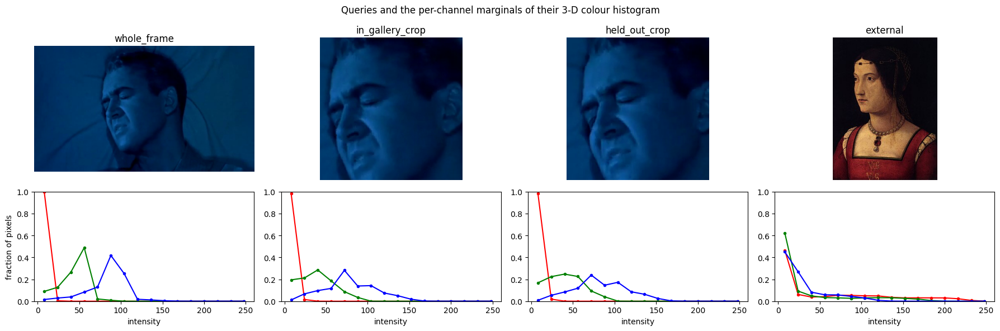

In [12]:
def marginals(h, bins=BINS_PER_CHANNEL):
    h = h.reshape(bins, bins, bins) / h.sum()
    return h.sum((1, 2)), h.sum((0, 2)), h.sum((0, 1))

fig, axes = plt.subplots(2, 4, figsize=(18, 6), gridspec_kw={"height_ratios": [1.3, 1]})
for i, name in enumerate(query_names):
    axes[0, i].imshow(queries[name]); axes[0, i].set_title(name); axes[0, i].axis("off")
    for m, c in zip(marginals(H_query[i]), "rgb"):
        axes[1, i].plot(np.arange(BINS_PER_CHANNEL) * 16 + 8, m, color=c, marker=".")
    axes[1, i].set_xlabel("intensity"); axes[1, i].set_ylim(0, 1)
axes[1, 0].set_ylabel("fraction of pixels")
fig.suptitle("Queries and the per-channel marginals of their 3-D colour histogram")
plt.tight_layout(); plt.show()

In [13]:
rgb_metrics = histogram_metrics(H_query, H_gallery)
checks_table({"cosine": rgb_metrics["cosine"].numpy()}, "RGB histogram +")

,whole_frame,in_gallery_crop,held_out_crop,external
RGB histogram +,,,,
cosine,PASS (first hit: 1),fail (first hit: 2),PASS (first hit: 1),fail (first hit: 56)


### Try 3: which metric?

In [14]:
checks_table({k: v.numpy() for k, v in rgb_metrics.items()}, "RGB histogram +")

,whole_frame,in_gallery_crop,held_out_crop,external
RGB histogram +,,,,
cosine,PASS (first hit: 1),fail (first hit: 2),PASS (first hit: 1),fail (first hit: 56)
Bhattacharyya,PASS (first hit: 1),fail (first hit: 2),PASS (first hit: 1),fail (first hit: 27)
-chi2,PASS (first hit: 1),fail (first hit: 3),PASS (first hit: 2),fail (first hit: 46)
-KL(query||gallery),PASS (first hit: 1),PASS (first hit: 1),PASS (first hit: 2),fail (first hit: 5)
intersection (normalised),PASS (first hit: 1),fail (first hit: 3),PASS (first hit: 2),fail (first hit: 48)
intersection (counts),PASS (first hit: 1),PASS (first hit: 1),PASS (first hit: 1),fail (first hit: 54)


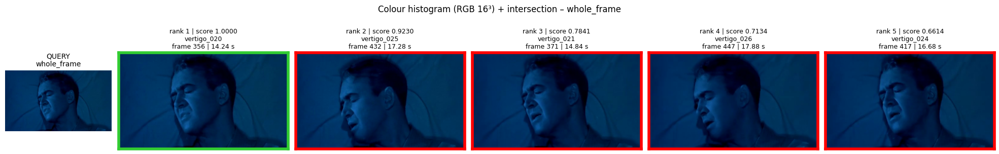

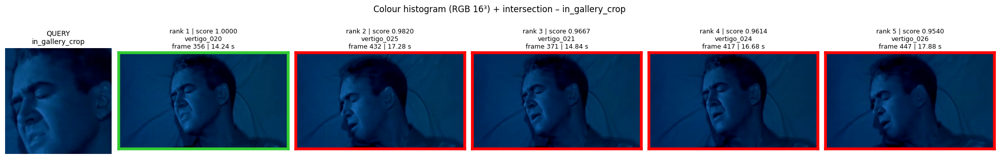

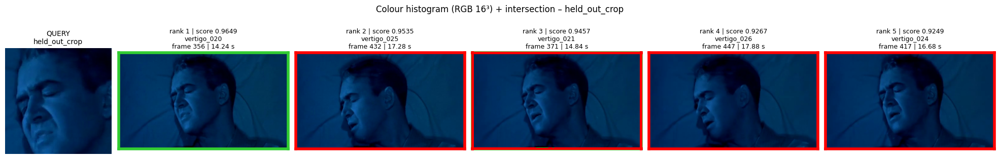

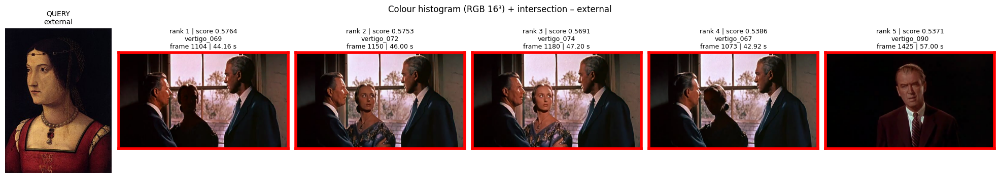

,query,criterion,passed,first relevant rank,top-5 frame indices,top-5 scores
colour hist + intersection,whole_frame,top-1,PASS,1,"[356, 432, 371, 447, 417]","[1.0, 0.923, 0.7841, 0.7134, 0.6614]"
colour hist + intersection,in_gallery_crop,top-1,PASS,1,"[356, 432, 371, 417, 447]","[1.0, 0.982, 0.9667, 0.9614, 0.954]"
colour hist + intersection,held_out_crop,top-3,PASS,1,"[356, 432, 371, 447, 417]","[0.9649, 0.9535, 0.9457, 0.9267, 0.9249]"
colour hist + intersection,external,top-3,FAIL,54,"[1104, 1150, 1180, 1073, 1425]","[0.5764, 0.5753, 0.5691, 0.5386, 0.5371]"


In [15]:
S_hist = rgb_metrics["intersection (counts)"].numpy()
for name in query_names:
    show_panel(name, S_hist[query_names.index(name)], "Colour histogram (RGB 16³) + intersection")
res_hist = report("colour hist + intersection", S_hist)
all_results.append(res_hist)
res_hist

## 5.2 ResNet-50 (ImageNet-1K V2)

### Try 1: global embedding with the official preprocessing

In [16]:
from torchvision.models import ResNet50_Weights, resnet50

weights = ResNet50_Weights.IMAGENET1K_V2
preprocess = weights.transforms()
model = resnet50(weights=weights)
model.fc = torch.nn.Identity()
model.eval().to(device)
print(preprocess)

@torch.inference_mode()
def embed(images, transform=preprocess, net=model, batch_size=32):
    out = []
    for start in range(0, len(images), batch_size):
        batch = torch.stack([transform(Image.fromarray(im)) for im in images[start:start + batch_size]])
        out.append(net(batch.to(device)).float().cpu())
    return F.normalize(torch.cat(out), dim=1)

t0 = time.time()
E_gallery = embed(gallery_images)
E_query = embed([queries[n] for n in query_names], batch_size=1)
t_resnet = time.time() - t0
print(f"gallery {tuple(E_gallery.shape)}, queries {tuple(E_query.shape)}, {t_resnet:.1f} s on {device}")

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


gallery (150, 2048), queries (4, 2048), 1.2 s on mps


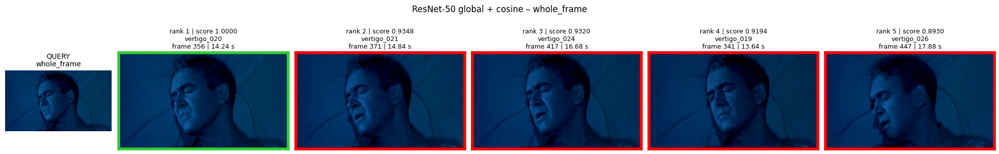

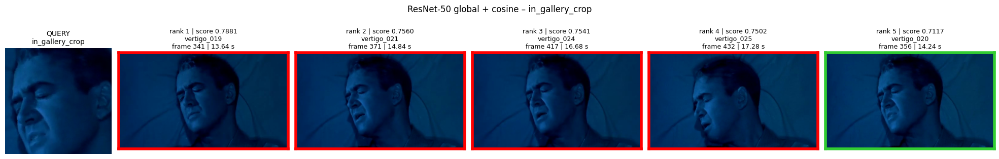

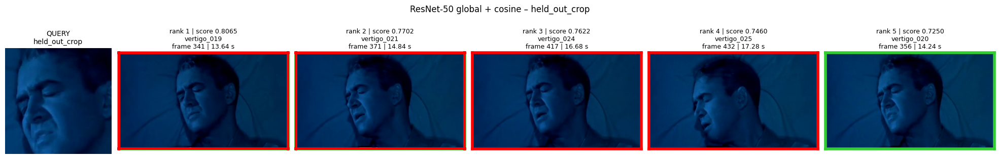

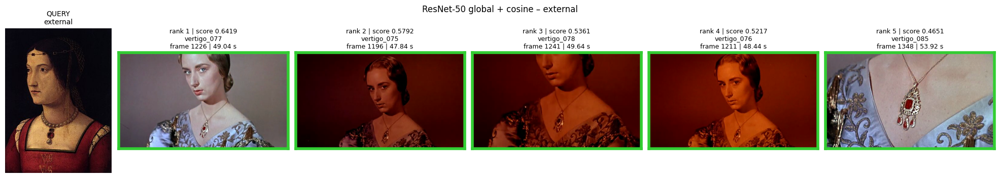

,query,criterion,passed,first relevant rank,top-5 frame indices,top-5 scores
ResNet-50 global + cosine,whole_frame,top-1,PASS,1,"[356, 371, 417, 341, 447]","[1.0, 0.9348, 0.932, 0.9194, 0.893]"
ResNet-50 global + cosine,in_gallery_crop,top-1,FAIL,5,"[341, 371, 417, 432, 356]","[0.7881, 0.756, 0.7541, 0.7502, 0.7117]"
ResNet-50 global + cosine,held_out_crop,top-3,FAIL,5,"[341, 371, 417, 432, 356]","[0.8065, 0.7702, 0.7622, 0.746, 0.725]"
ResNet-50 global + cosine,external,top-3,PASS,1,"[1226, 1196, 1241, 1211, 1348]","[0.6419, 0.5792, 0.5361, 0.5217, 0.4651]"


In [17]:
S_resnet = (E_query @ E_gallery.T).numpy()
for name in query_names:
    show_panel(name, S_resnet[query_names.index(name)], "ResNet-50 global + cosine")
res_resnet = report("ResNet-50 global + cosine", S_resnet)
all_results.append(res_resnet)
res_resnet

### Try 2: change the preprocessing

In [18]:
from torchvision import transforms as T

normalize = T.Normalize(mean=preprocess.mean, std=preprocess.std)

def letterbox(image, target_w=560, target_h=320):
    im = Image.fromarray(image)
    s = min(target_w / im.width, target_h / im.height)
    im = im.resize((round(im.width * s), round(im.height * s)), Image.Resampling.BICUBIC)
    canvas = Image.new("RGB", (target_w, target_h))
    canvas.paste(im, ((target_w - im.width) // 2, (target_h - im.height) // 2))
    return canvas

variants = {
    "official (resize 232 + centre crop 224)": preprocess,
    "no centre crop (short side 224)": T.Compose([T.Resize(224, antialias=True), T.ToTensor(), normalize]),
    "squash to 224x224": T.Compose([T.Resize((224, 224), antialias=True), T.ToTensor(), normalize]),
    "letterbox to 560x320 + official": T.Compose([T.Lambda(lambda im: letterbox(np.array(im))), preprocess]),
    "greyscale + official": T.Compose([T.Grayscale(num_output_channels=3), preprocess]),
}

S_variants = {
    vname: (embed([queries[n] for n in query_names], tf, batch_size=1) @ embed(gallery_images, tf).T).numpy()
    for vname, tf in variants.items()
}
checks_table(S_variants, "ResNet-50 preprocessing")

,whole_frame,in_gallery_crop,held_out_crop,external
ResNet-50 preprocessing,,,,
official (resize 232 + centre crop 224),PASS (first hit: 1),fail (first hit: 5),PASS (first hit: 1),PASS (first hit: 1)
no centre crop (short side 224),PASS (first hit: 1),fail (first hit: 4),PASS (first hit: 2),PASS (first hit: 1)
squash to 224x224,PASS (first hit: 1),fail (first hit: 3),PASS (first hit: 1),PASS (first hit: 1)
letterbox to 560x320 + official,PASS (first hit: 1),fail (first hit: 5),PASS (first hit: 1),PASS (first hit: 1)
greyscale + official,PASS (first hit: 1),fail (first hit: 7),fail (first hit: 4),PASS (first hit: 1)


### Try 3: region-based matching

In [19]:
def sliding_windows(h, w, sizes=(160, 200, 240), stride_ratio=0.25):
    boxes = []
    for s in sizes:
        step = int(s * stride_ratio)
        for top in range(0, h - s + 1, step):
            for left in range(0, w - s + 1, step):
                boxes.append((left, top, left + s, top + s))
    return boxes

boxes = sliding_windows(height, width)
print(len(boxes), "windows per frame, e.g. the 200-px ones:", [b for b in boxes if b[2] - b[0] == 200][:9], "...")

t0 = time.time()
window_crops = [np.array(Image.fromarray(im).crop(b)) for im in gallery_images for b in boxes]
E_windows = embed(window_crops, batch_size=64).view(len(gallery_images), len(boxes), -1)
t_region = time.time() - t0
print(f"window embeddings {tuple(E_windows.shape)}, computed in {t_region:.1f} s on {device}")

91 windows per frame, e.g. the 200-px ones: [(0, 0, 200, 200), (50, 0, 250, 200), (100, 0, 300, 200), (150, 0, 350, 200), (200, 0, 400, 200), (250, 0, 450, 200), (300, 0, 500, 200), (350, 0, 550, 200), (0, 50, 200, 250)] ...


window embeddings (150, 91, 2048), computed in 78.3 s on mps


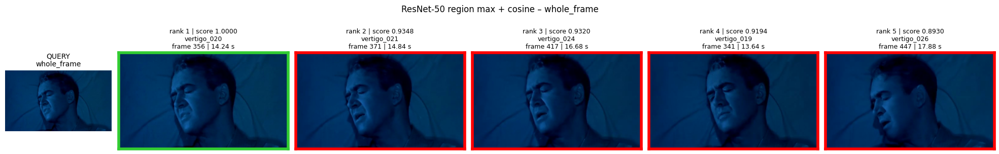

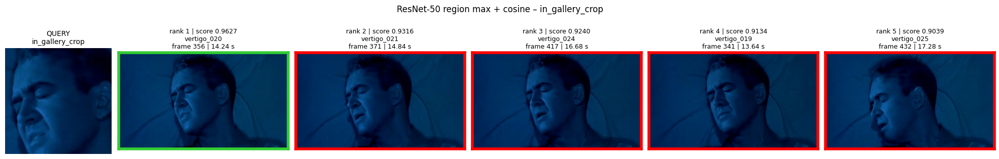

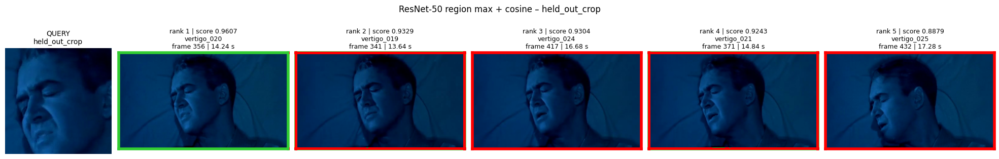

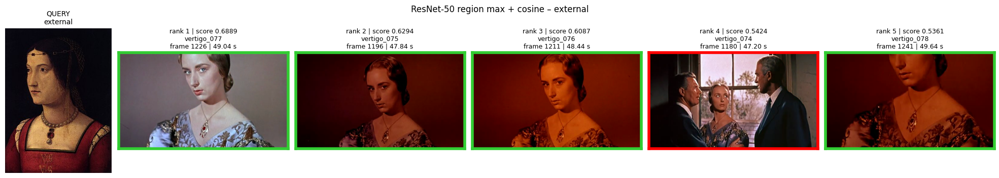

,query,criterion,passed,first relevant rank,top-5 frame indices,top-5 scores
ResNet-50 region max + cosine,whole_frame,top-1,PASS,1,"[356, 371, 417, 341, 447]","[1.0, 0.9348, 0.932, 0.9194, 0.893]"
ResNet-50 region max + cosine,in_gallery_crop,top-1,PASS,1,"[356, 371, 417, 341, 432]","[0.9627, 0.9316, 0.924, 0.9134, 0.9039]"
ResNet-50 region max + cosine,held_out_crop,top-3,PASS,1,"[356, 341, 417, 371, 432]","[0.9607, 0.9329, 0.9304, 0.9243, 0.8879]"
ResNet-50 region max + cosine,external,top-3,PASS,1,"[1226, 1196, 1211, 1180, 1241]","[0.6889, 0.6294, 0.6087, 0.5424, 0.5361]"


In [20]:
window_scores = torch.einsum("qd,gwd->qgw", E_query, E_windows)
best_window_score, best_window = window_scores.max(-1)
S_region = torch.maximum(best_window_score, E_query @ E_gallery.T).numpy()

for name in query_names:
    show_panel(name, S_region[query_names.index(name)], "ResNet-50 region max + cosine")
res_region = report("ResNet-50 region max + cosine", S_region)
all_results.append(res_region)
res_region

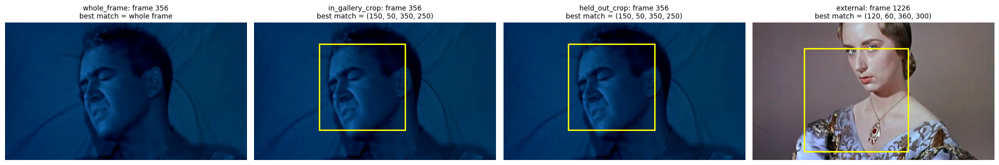

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for qi, name in enumerate(query_names):
    g = int(rank(S_region[qi])[0])
    ax = axes[qi]
    ax.imshow(gallery_images[g])
    global_wins = float(E_query[qi] @ E_gallery[g]) >= float(best_window_score[qi, g])
    if not global_wins:
        l, t, r, b = boxes[int(best_window[qi, g])]
        ax.add_patch(patches.Rectangle((l, t), r - l, b - t, fill=False, edgecolor="yellow", lw=2))
    where = "whole frame" if global_wins else boxes[int(best_window[qi, g])]
    ax.set_title(f"{name}: frame {gallery_frame_idx[g]}\nbest match = {where}", fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5.3 Optional: DINOv2 ViT-S/14

In [22]:
import timm

dino = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True, num_classes=0, img_size=224).eval().to(device)
cfg = timm.data.resolve_data_config({}, model=dino)
cfg.update(input_size=(3, 224, 224), crop_pct=224 / 256)
dino_preprocess = timm.data.create_transform(**cfg)
print(dino_preprocess)

t0 = time.time()
D_gallery = embed(gallery_images, dino_preprocess, dino)
D_query = embed([queries[n] for n in query_names], dino_preprocess, dino, batch_size=1)
t_dino = time.time() - t0
print(f"DINOv2 embeddings {tuple(D_gallery.shape)}, {t_dino:.1f} s on {device}")
print(f"parameters: DINOv2 ViT-S/14 = {sum(p.numel() for p in dino.parameters()) / 1e6:.1f} M, "
      f"ResNet-50 = {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

Compose(
    Resize(size=256, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


DINOv2 embeddings (150, 384), 1.3 s on mps
parameters: DINOv2 ViT-S/14 = 21.6 M, ResNet-50 = 23.5 M


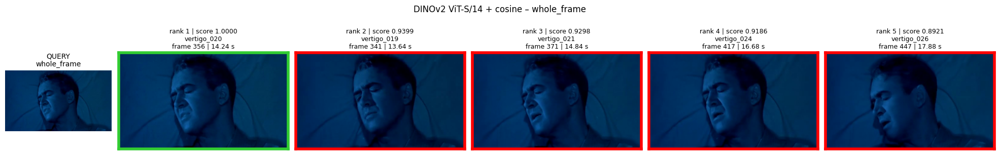

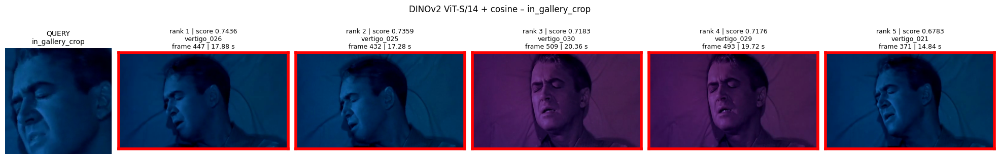

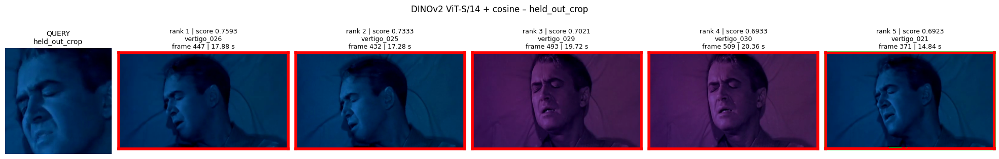

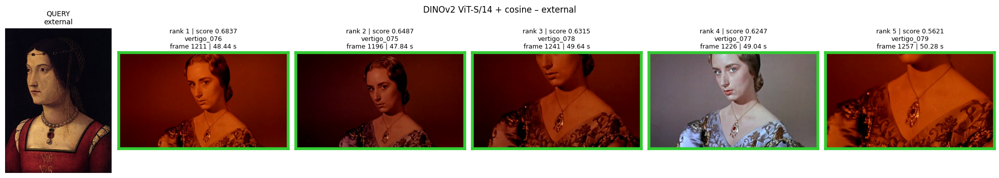

,query,criterion,passed,first relevant rank,top-5 frame indices,top-5 scores
DINOv2 ViT-S/14 + cosine,whole_frame,top-1,PASS,1,"[356, 341, 371, 417, 447]","[1.0, 0.9399, 0.9298, 0.9186, 0.8921]"
DINOv2 ViT-S/14 + cosine,in_gallery_crop,top-1,FAIL,7,"[447, 432, 509, 493, 371]","[0.7436, 0.7359, 0.7183, 0.7176, 0.6783]"
DINOv2 ViT-S/14 + cosine,held_out_crop,top-3,FAIL,7,"[447, 432, 493, 509, 371]","[0.7593, 0.7333, 0.7021, 0.6933, 0.6923]"
DINOv2 ViT-S/14 + cosine,external,top-3,PASS,1,"[1211, 1196, 1241, 1226, 1257]","[0.6837, 0.6487, 0.6315, 0.6247, 0.5621]"


In [23]:
S_dino = (D_query @ D_gallery.T).numpy()
for name in query_names:
    show_panel(name, S_dino[query_names.index(name)], "DINOv2 ViT-S/14 + cosine")
res_dino = report("DINOv2 ViT-S/14 + cosine", S_dino)
all_results.append(res_dino)
res_dino

## 6. Summary of all methods

In [24]:
summary = pd.DataFrame({
    df.index[0]: {r["query"]: f'{r["passed"]} (rank {r["first relevant rank"]})' for _, r in df.iterrows()}
    for df in all_results
}).T
summary["passed"] = summary.apply(lambda r: sum(v.startswith("PASS") for v in r), axis=1).astype(str) + " / 4"
summary

,whole_frame,in_gallery_crop,held_out_crop,external,passed
colour hist + intersection,PASS (rank 1),PASS (rank 1),PASS (rank 1),FAIL (rank 54),3 / 4
ResNet-50 global + cosine,PASS (rank 1),FAIL (rank 5),FAIL (rank 5),PASS (rank 1),2 / 4
ResNet-50 region max + cosine,PASS (rank 1),PASS (rank 1),PASS (rank 1),PASS (rank 1),4 / 4
DINOv2 ViT-S/14 + cosine,PASS (rank 1),FAIL (rank 7),FAIL (rank 7),PASS (rank 1),2 / 4


In [25]:
rows = []
for df, S in zip(all_results, [S_hist, S_resnet, S_region, S_dino]):
    row = {"method": df.index[0]}
    for name in ["in_gallery_crop", "held_out_crop"]:
        s = S[query_names.index(name)]
        rel = np.array([is_relevant(name, g) for g in range(len(gallery))])
        row[f"{name}: gap"] = round(float(s[rel].max() - s[~rel].max()), 4)
    rows.append(row)
pd.DataFrame(rows).set_index("method")

,in_gallery_crop: gap,held_out_crop: gap
method,,
colour hist + intersection,0.0180,0.0115
ResNet-50 global + cosine,-0.0764,-0.0815
ResNet-50 region max + cosine,0.0311,0.0278
DINOv2 ViT-S/14 + cosine,-0.0708,-0.0900
